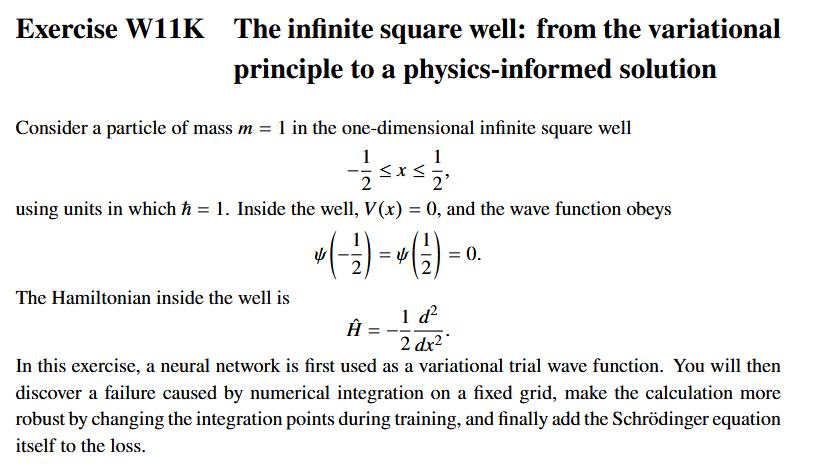

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
 
class WaveNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 16),
            nn.SiLU(),
            nn.Linear(16, 16),
            nn.SiLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return (0.25 - x**2) * self.net(x)

    def get_derivatives(self, x, order=1):
        psi = self(x)
        dpsi_dx = torch.autograd.grad(psi, x, grad_outputs=torch.ones_like(psi), create_graph=True)[0]
        
        if order == 1:
            return psi, dpsi_dx
            
        d2psi_dx2 = torch.autograd.grad(dpsi_dx, x, grad_outputs=torch.ones_like(dpsi_dx), create_graph=True)[0]
        return psi, dpsi_dx, d2psi_dx2

def calculate_energy(x, psi, dpsi_dx):
    kinetic = 0.5 * torch.trapezoid(dpsi_dx.squeeze()**2, x.squeeze())
    norm = torch.trapezoid(psi.squeeze()**2, x.squeeze())
    return kinetic / norm

learning_rates = [1e-2, 1e-3, 1e-4]
x_dense = torch.linspace(-0.5, 0.5, 200).view(-1, 1).requires_grad_(True)

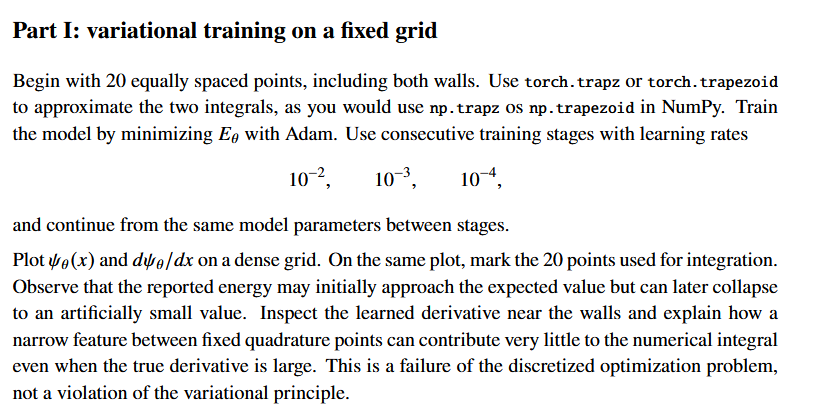

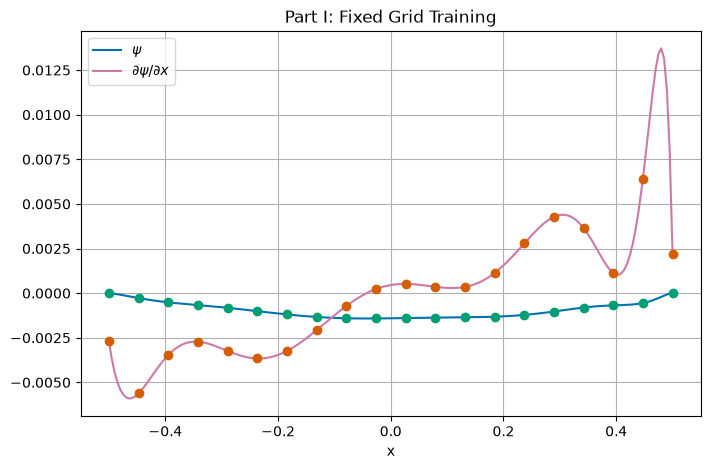

In [2]:
model_fixed = WaveNet()
x_fixed = torch.linspace(-0.5, 0.5, 20).view(-1, 1).requires_grad_(True)

for lr in learning_rates:
    optimizer = torch.optim.Adam(model_fixed.parameters(), lr=lr)
    for epoch in range(2000):
        optimizer.zero_grad()
        psi, dpsi = model_fixed.get_derivatives(x_fixed, order=1)
        loss = calculate_energy(x_fixed, psi, dpsi)
        loss.backward()
        optimizer.step()

model_fixed.eval()
psi_dense, dpsi_dense = model_fixed.get_derivatives(x_dense, order=1)
psi_dots, dpsi_dots = model_fixed.get_derivatives(x_fixed, order=1)
    
plt.figure(figsize=(8, 5))
plt.plot(x_dense.detach().numpy(), psi_dense.detach().numpy(), label=r'$\psi$', color='#0072B2')
plt.plot(x_dense.detach().numpy(), dpsi_dense.detach().numpy(), label=r'$\partial\psi/\partial x$', color='#CC79A7')
plt.scatter(x_fixed.detach().numpy(), psi_dots.detach().numpy(), color='#009E73', zorder=5)
plt.scatter(x_fixed.detach().numpy(), dpsi_dots.detach().numpy(), color='#D55E00', zorder=5)
plt.xlabel("x")
plt.grid(True)
plt.legend()
plt.title("Part I: Fixed Grid Training")
plt.show()

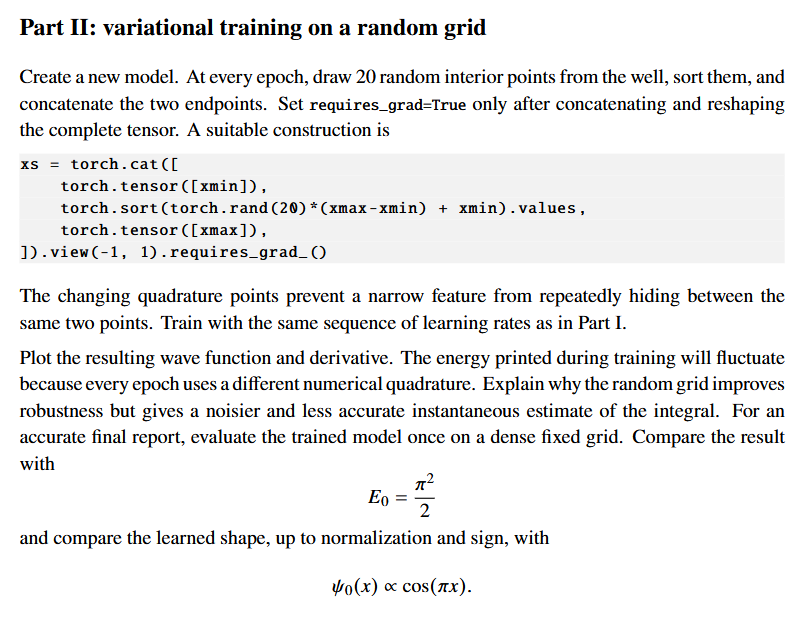

Part II Final Energy: 5.0824 (Expected: 4.9348)


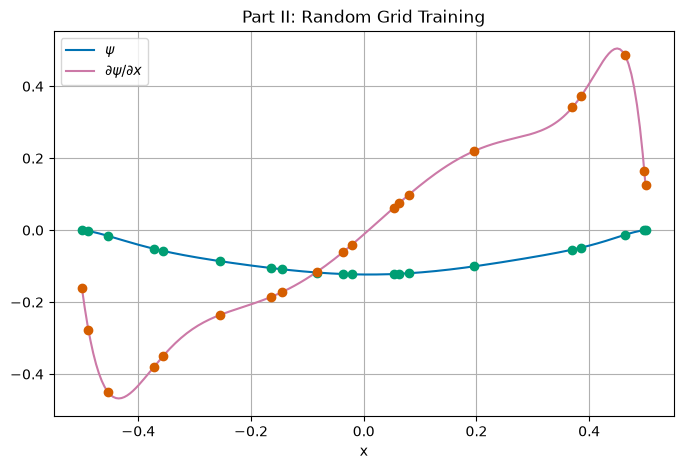

In [3]:
model_random = WaveNet()

for lr in learning_rates:
    optimizer = torch.optim.Adam(model_random.parameters(), lr=lr)
    for epoch in range(2000):
        optimizer.zero_grad()
        
        x_inner = torch.sort(torch.rand(18) - 0.5).values
        x_random = torch.cat([
            torch.tensor([-0.5]), 
            x_inner, 
            torch.tensor([0.5])
        ]).view(-1, 1).requires_grad_(True)
        
        psi, dpsi = model_random.get_derivatives(x_random, order=1)
        loss = calculate_energy(x_random, psi, dpsi)
        loss.backward()
        optimizer.step()

model_random.eval()
psi_dense, dpsi_dense = model_random.get_derivatives(x_dense, order=1)
E_final_random = calculate_energy(x_dense, psi_dense, dpsi_dense).item()

x_inner_plot = torch.sort(torch.rand(18) - 0.5).values
x_dots = torch.cat([torch.tensor([-0.5]), x_inner_plot, torch.tensor([0.5])]).view(-1, 1).requires_grad_(True)
psi_dots, dpsi_dots = model_random.get_derivatives(x_dots, order=1)

print(f"Part II Final Energy: {E_final_random:.4f} (Expected: {math.pi**2 / 2:.4f})")

plt.figure(figsize=(8, 5))
plt.plot(x_dense.detach().numpy(), psi_dense.detach().numpy(), label=r'$\psi$', color='#0072B2')
plt.plot(x_dense.detach().numpy(), dpsi_dense.detach().numpy(), label=r'$\partial\psi/\partial x$', color='#CC79A7')
plt.scatter(x_dots.detach().numpy(), psi_dots.detach().numpy(), color='#009E73', zorder=5)
plt.scatter(x_dots.detach().numpy(), dpsi_dots.detach().numpy(), color='#D55E00', zorder=5)
plt.xlabel("x")
plt.grid(True)
plt.legend()
plt.title("Part II: Random Grid Training")
plt.show()

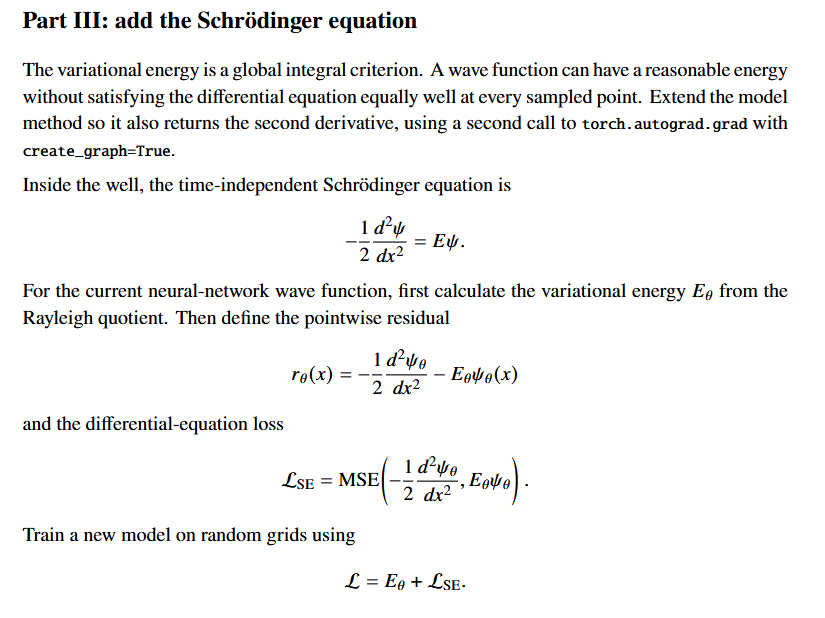
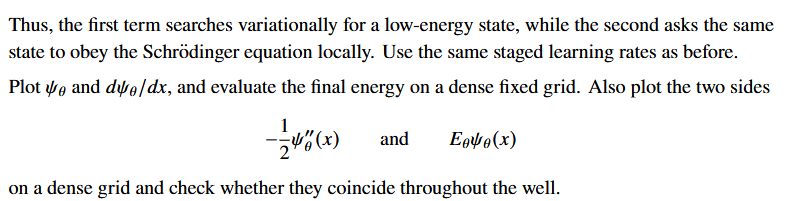

Part III Final Energy: 5.0296 (Expected: 4.9348)


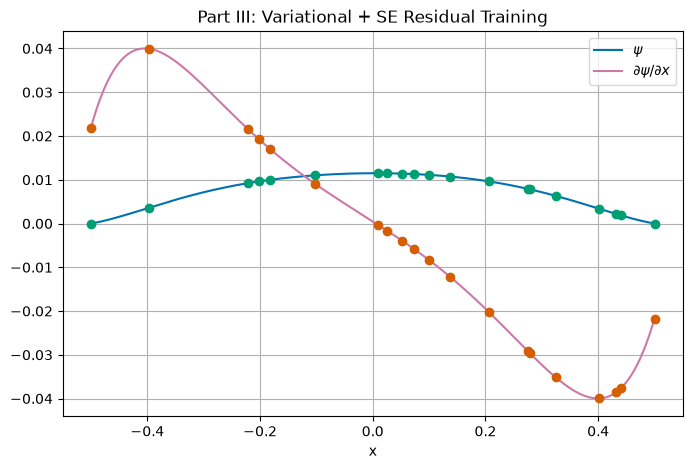

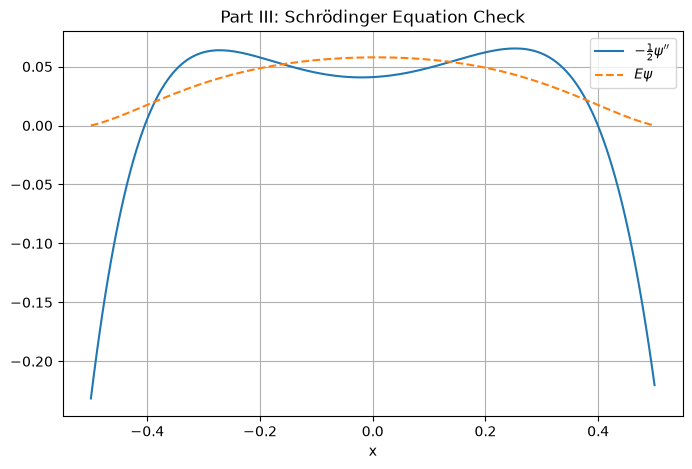

In [4]:
model_se = WaveNet()

for lr in learning_rates:
    optimizer = torch.optim.Adam(model_se.parameters(), lr=lr)
    for epoch in range(2000):
        optimizer.zero_grad()
        
        x_inner = torch.sort(torch.rand(18) - 0.5).values
        x_random = torch.cat([
            torch.tensor([-0.5]), 
            x_inner, 
            torch.tensor([0.5])
        ]).view(-1, 1).requires_grad_(True)
        
        psi, dpsi, ddpsi = model_se.get_derivatives(x_random, order=2)
        E = calculate_energy(x_random, psi, dpsi)
        
        loss_se = torch.nn.functional.mse_loss(-0.5 * ddpsi, E * psi)
        loss = E + loss_se
        
        loss.backward()
        optimizer.step()

model_se.eval()
psi_dense, dpsi_dense, ddpsi_dense = model_se.get_derivatives(x_dense, order=2)
E_final_se = calculate_energy(x_dense, psi_dense, dpsi_dense).item()

x_inner_plot = torch.sort(torch.rand(18) - 0.5).values
x_dots = torch.cat([torch.tensor([-0.5]), x_inner_plot, torch.tensor([0.5])]).view(-1, 1).requires_grad_(True)
psi_dots, dpsi_dots = model_se.get_derivatives(x_dots, order=1)

print(f"Part III Final Energy: {E_final_se:.4f} (Expected: {math.pi**2 / 2:.4f})")

plt.figure(figsize=(8, 5))
plt.plot(x_dense.detach().numpy(), psi_dense.detach().numpy(), label=r'$\psi$', color='#0072B2')
plt.plot(x_dense.detach().numpy(), dpsi_dense.detach().numpy(), label=r'$\partial\psi/\partial x$', color='#CC79A7')
plt.scatter(x_dots.detach().numpy(), psi_dots.detach().numpy(), color='#009E73', zorder=5)
plt.scatter(x_dots.detach().numpy(), dpsi_dots.detach().numpy(), color='#D55E00', zorder=5)
plt.xlabel("x")
plt.grid(True)
plt.legend()
plt.title("Part III: Variational + SE Residual Training")
plt.show()

plt.figure(figsize=(8, 5))
lhs = -0.5 * ddpsi_dense.detach().numpy()
rhs = E_final_se * psi_dense.detach().numpy()
plt.plot(x_dense.detach().numpy(), lhs, label=r'$-\frac{1}{2}\psi^{\prime\prime}$')
plt.plot(x_dense.detach().numpy(), rhs, label=r'$E\psi$', linestyle='dashed')
plt.xlabel("x")
plt.grid(True)
plt.legend()
plt.title("Part III: Schrödinger Equation Check")
plt.show()

### Code Explanation

The `WaveNet` architecture implements a fully connected network with two hidden layers of width 16 and SiLU activations. The output is multiplied by the prefactor $(\frac{1}{4} - x^2)$. This prefactor mathematically guarantees that the boundary conditions are exact because it evaluates to zero at the walls $x = -0.5$ and $x = 0.5$, forcing $\psi_\theta(x)$ to zero regardless of the neural network's parameters.

The Rayleigh quotient is calculated using `torch.trapezoid` to approximate the continuous integrals. Because the quotient divides the expectation of the Hamiltonian by the norm of the wave function, any nonzero constant multiplier $c$ applied to $\psi_\theta$ will simply factor out as $c^2/c^2$ and cancel. This makes the energy invariant to scale, eliminating the need for a separate normalization penalty during training.

The training loop supports three modes, sequentially stepping through learning rates of $10^{-2}, 10^{-3},$ and $10^{-4}$:

1. **Fixed**: Evaluates the integrals on 20 equally spaced stationary points.


2. **Random**: Draws 20 random points (keeping the endpoints fixed) every epoch to prevent the network from memorizing the quadrature gaps.


3. **SE (Schrödinger Equation)**: Calculates the second derivative to form the local pointwise residual $-\frac{1}{2}\psi^{\prime\prime}(x) - E_\theta \psi(x)$. The training loss minimizes both the variational energy $E_\theta$ and the Mean Squared Error of this residual.



### Reflection Questions

* **Integration by parts and derivatives:** Applying integration by parts to $\int \psi \psi^{\prime\prime} dx$ transfers one derivative from $\psi^{\prime\prime}$ onto the other $\psi$, transforming the integrand into $(\psi^\prime)^2$ and eliminating the boundary terms. This reduces the computational requirement from needing a second derivative down to only needing the first derivative for the variational energy.


* **The fixed-grid loophole:** The fixed discrete grid can be exploited because numerical quadrature (like the trapezoidal rule) only evaluates the function exactly at the grid points. The network can learn to place narrow, jagged features or massive derivative spikes entirely in the gaps between the 20 fixed points, artificially lowering the computed discrete energy without penalty.


* **Random grid robustness vs. fluctuation:** Changing the grid every epoch prevents sharp features from repeatedly hiding between the same two points, improving robustness. However, because each random sample provides a slightly different numerical approximation of the continuous integral, the reported training energy fluctuates from epoch to epoch.


* **Dense grid evaluation:** A dense fixed grid is highly useful for final evaluation because having a massive number of points (e.g., 200) minimizes the numerical integration error, providing an accurate calculation of the true integral for the fully trained wave function.


* **Additional SE information:** The local Schrödinger-equation residual adds a pointwise constraint, asking the state to obey the differential equation locally at every evaluated coordinate rather than just satisfying a global, averaged integral criterion.


* **Model equivalence:** Both the model minimizing only the variational energy (on random grids) and the model combining it with the SE residual should theoretically produce the same ground-state shape $\psi_0(x) \propto \cos(\pi x)$ and the same minimum energy $E_0 = \frac{\pi^2}{2}$.


* **Irrelevant amplitude and sign:** The overall amplitude and sign are physically irrelevant because the wave function represents a probability distribution when normalized, and the Schrödinger equation is a linear homogeneous equation. A scaled or flipped wave function describes the exact same physical quantum state.